# Session 23 Solutions: Distributions and Outliers

Data Science with Python, Level 2, Stage 3: Exploring Data

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
flats = pd.read_csv(DATA_URL + "apartments.csv")

## In-Class Exercises

### In-Class Exercise 1: Area Distribution

96.2 96.0 0.16


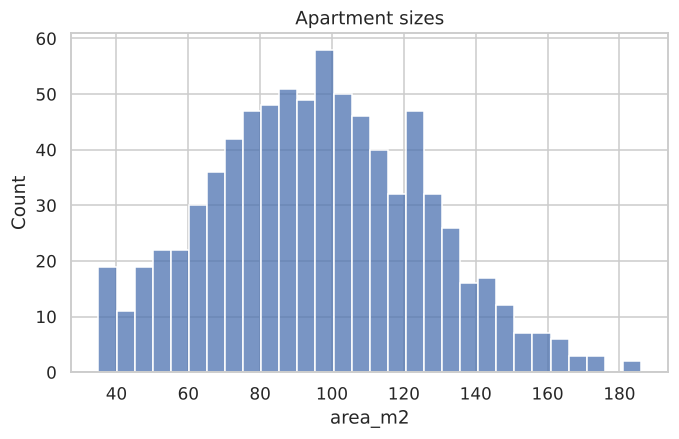

In [2]:
sns.histplot(data=flats, x="area_m2", bins=30)
plt.title("Apartment sizes")
plt.show()
print(round(flats["area_m2"].mean(), 1), flats["area_m2"].median(), round(flats["area_m2"].skew(), 2))

### In-Class Exercise 2: A Reusable Rule

In [3]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

print(iqr_outliers(flats["area_m2"]).sum(), iqr_outliers(flats["distance_center_km"]).sum())

2 0


### In-Class Exercise 3: Weekly Hours

In [4]:
emp = pd.read_csv(DATA_URL + "employees.csv")
g = emp.groupby("city")["monthly_salary"]
emp["z_city"] = (emp["monthly_salary"] - g.transform("mean")) / g.transform("std")
emp.loc[emp["z_city"] > 2.5, ["name", "city", "department", "monthly_salary"]]

,name,city,department,monthly_salary
2,Dana Nassar,Dubai,Engineering,4940
48,Adam Bakri,Cairo,Engineering,3750
103,Sami Karam,Beirut,Engineering,3640
104,Yazan Najjar,Dubai,Engineering,4810
223,Tariq Aziz,Amman,Engineering,4190
339,Basel Haddad,Amman,Engineering,4070


### In-Class Exercise 4: Cap and Compare

In [5]:
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
lo, hi = bikes["rentals"].quantile([0.01, 0.99])
capped = bikes["rentals"].clip(lower=lo, upper=hi)
print(round(bikes["rentals"].mean(), 1), round(capped.mean(), 1))
print(round(bikes["rentals"].std(), 1), round(capped.std(), 1))

4010.7 4011.4
1633.3 1624.6


## Part A: Basic

### Exercise 1: Mean or Median?

In [6]:
for col in ["area_m2", "building_age", "distance_center_km", "price_k"]:
    s = flats[col]
    print(f"{col:<20} mean {s.mean():7.1f}  median {s.median():7.1f}  skew {s.skew():5.2f}")
# Report the median for price_k, which is strongly skewed; the others are close to symmetric.

area_m2              mean    96.2  median    96.0  skew  0.16
building_age         mean    22.0  median    22.0  skew -0.05
distance_center_km   mean     5.2  median     5.5  skew -0.01
price_k              mean    98.7  median    92.8  skew  1.93


### Exercise 2: Box Plot of Ages

0


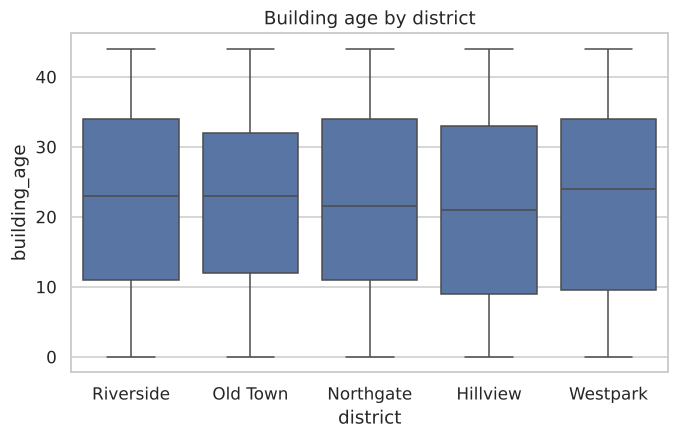

In [7]:
sns.boxplot(data=flats, x="district", y="building_age")
plt.title("Building age by district")
plt.show()
q1, q3 = flats["building_age"].quantile([0.25, 0.75])
iqr = q3 - q1
print(((flats["building_age"] < q1 - 1.5 * iqr) | (flats["building_age"] > q3 + 1.5 * iqr)).sum())

## Part B: Intermediate

### Exercise 3: Exam Score Outliers

In [8]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
m = exams["math"]
q1, q3 = m.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_mask = (m < q1 - 1.5 * iqr) | (m > q3 + 1.5 * iqr)
z_mask = ((m - m.mean()) / m.std()).abs() > 3
print(exams.loc[iqr_mask, ["math", "study_hours_week", "attendance_pct"]])
print(z_mask.sum(), "with |z| > 3")
# The very low and very high scores mostly match very little or very much study time.

     math  study_hours_week  attendance_pct
158    11               3.2              97
214    92               4.5             100
263    93              19.7              93
299    17               4.1              92
393    95              18.7             100
397    20               6.3              84
1 with |z| > 3


### Exercise 4: Skewed Salaries

income      mean   1310.29 median   1109.68 skew  2.06
log income  mean      7.00 median      7.01 skew -0.02


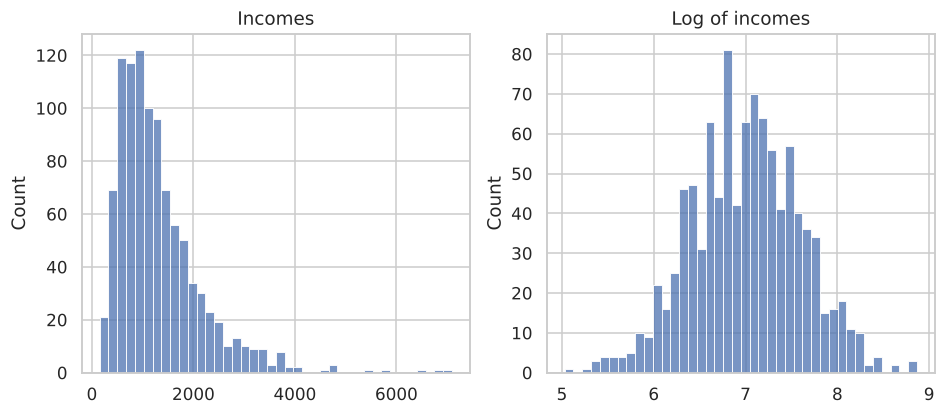

In [9]:
incomes = pd.Series(np.random.default_rng(5).lognormal(mean=7, sigma=0.6, size=1000))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(incomes, bins=40, ax=axes[0])
axes[0].set_title("Incomes")
sns.histplot(np.log(incomes), bins=40, ax=axes[1])
axes[1].set_title("Log of incomes")
plt.show()
for name, s in [("income", incomes), ("log income", np.log(incomes))]:
    print(f"{name:<11} mean {s.mean():9.2f} median {s.median():9.2f} skew {s.skew():5.2f}")

## Part C: Challenge

### Exercise 5: An Outlier Report Function

In [10]:
def outlier_report(df, column, group=None):
    s = df[column]
    if group is None:
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
    else:
        g = df.groupby(group)[column]
        q1, q3 = g.transform(lambda x: x.quantile(0.25)), g.transform(lambda x: x.quantile(0.75))
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = df[(s < low) | (s > high)].copy()
    hi = high if group is None else high[out.index]
    lo = low if group is None else low[out.index]
    out["beyond_fence"] = np.where(out[column] > hi, out[column] - hi, out[column] - lo)
    return out.sort_values("beyond_fence", ascending=False)

print(len(outlier_report(flats, "price_k")))
outlier_report(flats, "price_k", group="district")[["district", "area_m2", "price_k", "beyond_fence"]].round(1)

19


,district,area_m2,price_k,beyond_fence
219,Riverside,143,413.2,203.7
438,Riverside,94,382.7,173.2
350,Hillview,110,328.4,160.4
600,Old Town,87,347.0,111.5
719,Westpark,115,202.2,70.6
290,Northgate,173,173.8,29.5
309,Westpark,158,146.5,14.9
481,Hillview,149,178.6,10.6
54,Westpark,68,137.5,5.9
175,Northgate,185,148.8,4.5


## Part D: Cumulative Project: City Bikes

### Exercise 6: City Bikes: Unusual Days

           date  season weather  temp_c  wind_kmh  rentals
418  2024-02-23  Winter   Clear    16.3       2.0     6030
619  2024-09-11  Autumn    Rain    22.4      11.1     3628


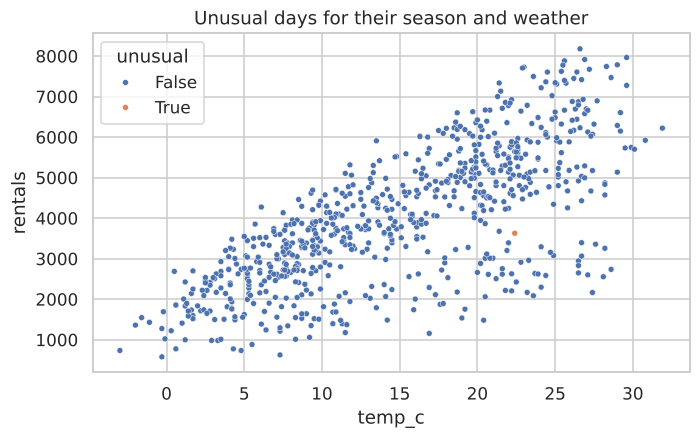

In [11]:
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
g = bikes.groupby(["season", "weather"])["rentals"]
q1, q3 = g.transform(lambda s: s.quantile(0.25)), g.transform(lambda s: s.quantile(0.75))
iqr = q3 - q1
bikes["unusual"] = (bikes["rentals"] < q1 - 1.5 * iqr) | (bikes["rentals"] > q3 + 1.5 * iqr)
print(bikes.loc[bikes["unusual"], ["date", "season", "weather", "temp_c", "wind_kmh", "rentals"]])
sns.scatterplot(data=bikes, x="temp_c", y="rentals", hue="unusual", s=15)
plt.title("Unusual days for their season and weather")
plt.show()
# Several unusual low days are very windy, which keeps riders away even in good weather.
# Some are from early 2023, before the bike scheme grew, so they look low compared with 2024.

## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | The few large values pull the mean up. |
| 2 | C | IQR is 20, and 60 + 1.5 x 20 = 90. |
| 3 | B | z counts standard deviations from the mean. |
| 4 | C | An impossible value is an error, not a real outlier. |
| 5 | B | A high price can be normal in one district and odd in another. |